<a href="https://colab.research.google.com/github/crsah234/anyangUniverSity_Third_second/blob/main/%EC%9D%91%EC%9A%A9%ED%9A%8C%EA%B7%80%EB%B6%84%EC%84%9D_%EB%8C%80%ED%9A%8C%EC%9A%A93.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 수면 데이터 불러오기
sleep = pd.read_sas(
    "/content/drive/MyDrive/안양대학교_데이터처리실무(3학년2학기)/SLQ_J.xpt"
)

# 우울 증상 데이터 불러오기
depression = pd.read_sas(
    "/content/drive/MyDrive/안양대학교_데이터처리실무(3학년2학기)/DPQ_J.xpt"
)

print("===== 수면 데이터 =====")
print("크기:", sleep.shape)
print("변수:")
print(sleep.columns.tolist())

print("\n===== 우울 증상 데이터 =====")
print("크기:", depression.shape)
print("변수:")
print(depression.columns.tolist())

===== 수면 데이터 =====
크기: (6161, 11)
변수:
['SEQN', 'SLQ300', 'SLQ310', 'SLD012', 'SLQ320', 'SLQ330', 'SLD013', 'SLQ030', 'SLQ040', 'SLQ050', 'SLQ120']

===== 우울 증상 데이터 =====
크기: (5533, 11)
변수:
['SEQN', 'DPQ010', 'DPQ020', 'DPQ030', 'DPQ040', 'DPQ050', 'DPQ060', 'DPQ070', 'DPQ080', 'DPQ090', 'DPQ100']


In [ ]:
# 수면 데이터 주요 변수
# - SLD012: 평일 수면시간
# - SLD013: 주말 수면시간
# - SLQ030, SLQ040, SLQ050: 수면 관련 문항
# - SLQ120: 주간 졸림 관련 문항
# 우울 증상 데이터
# - DPQ010 ~ DPQ090: PHQ-9 우울 증상 문항
# - DPQ100: 기능적 어려움 관련 문항

In [4]:
#### SLQ120 분포 확인
print("===== SLQ120 빈도수 =====")
print(sleep['SLQ120'].value_counts(dropna=False).sort_index())

print("\n===== SLQ120 비율(%) =====")
print(sleep['SLQ120'].value_counts(
    normalize=True, dropna=False
).sort_index() * 100)

print("\n===== 결측치 =====")
print("결측치 수:", sleep['SLQ120'].isna().sum())
print("결측률(%):", sleep['SLQ120'].isna().mean() * 100)

===== SLQ120 빈도수 =====
SLQ120
5.397605e-79    1028
1.000000e+00    1468
2.000000e+00    2059
3.000000e+00    1066
4.000000e+00     528
9.000000e+00      12
Name: count, dtype: int64

===== SLQ120 비율(%) =====
SLQ120
5.397605e-79    16.685603
1.000000e+00    23.827301
2.000000e+00    33.419899
3.000000e+00    17.302386
4.000000e+00     8.570037
9.000000e+00     0.194774
Name: proportion, dtype: float64

===== 결측치 =====
결측치 수: 0
결측률(%): 0.0


In [ ]:
# 종속변수 정제

In [5]:
# SAS 특수 결측값 처리
sleep['SLQ120'] = sleep['SLQ120'].replace(
    5.397605e-79, 0
)

# 무응답 코드 9를 결측 처리
sleep['SLQ120'] = sleep['SLQ120'].replace(9, np.nan)

# 정제 결과 확인
print(sleep['SLQ120'].value_counts(dropna=False).sort_index())

print("\n유효 관측치:", sleep['SLQ120'].notna().sum())
print("결측치:", sleep['SLQ120'].isna().sum())

SLQ120
5.397605e-79    1028
1.000000e+00    1468
2.000000e+00    2059
3.000000e+00    1066
4.000000e+00     528
NaN               12
Name: count, dtype: int64

유효 관측치: 6149
결측치: 12


In [6]:
# 0에 해당하는 SAS 특수값을 명시적으로 변환
# 1. 0값 변환 확인 및 수정
sleep.loc[
    sleep['SLQ120'].abs() < 1e-70,
    'SLQ120'
] = 0

print(sleep['SLQ120'].value_counts(dropna=False).sort_index())

SLQ120
0.0    1028
1.0    1468
2.0    2059
3.0    1066
4.0     528
NaN      12
Name: count, dtype: int64


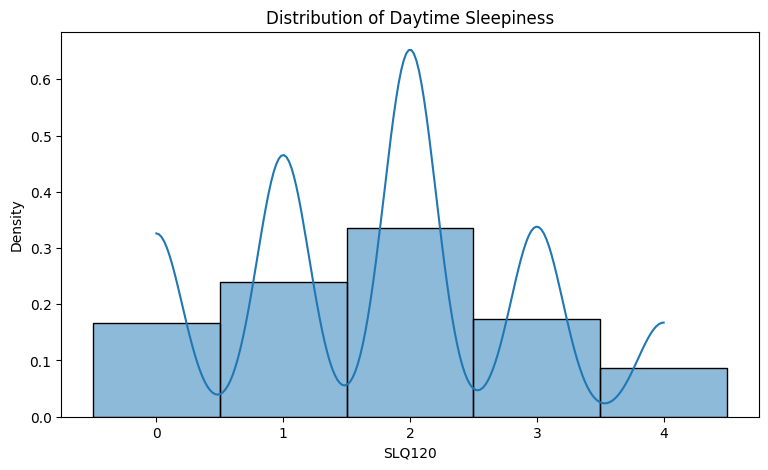

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.histplot(
    data=sleep,
    x='SLQ120',
    bins=np.arange(-0.5, 5.5, 1),
    stat='density',
    kde=True
)

plt.xticks([0, 1, 2, 3, 4])
plt.title('Distribution of Daytime Sleepiness')
plt.xlabel('SLQ120')
plt.ylabel('Density')
plt.show()

In [10]:
#### 독립변수 후보인 평일 수면시간(SLD012)
print("===== SLD012 기초통계량 =====")
print(sleep['SLD012'].describe())

print("\n===== 결측치 =====")
print(sleep['SLD012'].isna().sum())

print("\n===== 고유값 =====")
print(sorted(sleep['SLD012'].dropna().unique()))

===== SLD012 기초통계량 =====
count    6113.000000
mean        7.658842
std         1.669706
min         2.000000
25%         7.000000
50%         8.000000
75%         8.500000
max        14.000000
Name: SLD012, dtype: float64

===== 결측치 =====
48

===== 고유값 =====
[np.float64(2.0), np.float64(3.0), np.float64(3.5), np.float64(4.0), np.float64(4.5), np.float64(5.0), np.float64(5.5), np.float64(6.0), np.float64(6.5), np.float64(7.0), np.float64(7.5), np.float64(8.0), np.float64(8.5), np.float64(9.0), np.float64(9.5), np.float64(10.0), np.float64(10.5), np.float64(11.0), np.float64(11.5), np.float64(12.0), np.float64(12.5), np.float64(13.0), np.float64(13.5), np.float64(14.0)]


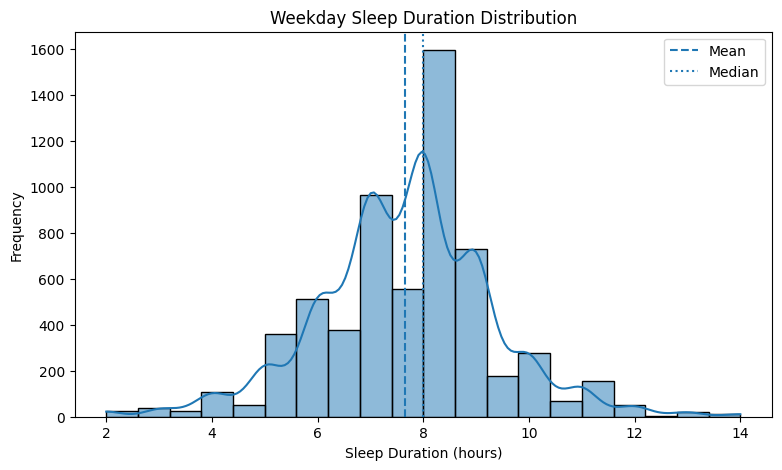

In [11]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=sleep,
    x='SLD012',
    bins=20,
    kde=True
)

plt.axvline(
    sleep['SLD012'].mean(),
    linestyle='--',
    label='Mean'
)

plt.axvline(
    sleep['SLD012'].median(),
    linestyle=':',
    label='Median'
)

plt.title('Weekday Sleep Duration Distribution')
plt.xlabel('Sleep Duration (hours)')
plt.ylabel('Frequency')
plt.legend()
plt.show()